# now we are making the lesson 6 road to the top 1 notebook , lets go (paddy doctor com(plant diseases)

In [5]:
#cell that have all of the imports
# Data
import numpy as np
import pandas as pd

# visualization
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# pytorch
import torch
import torch.nn.functional as F
from torch import nn, tensor
from torch.utils.data import DataLoader, Dataset

# torchvision
from torchvision import transforms, models
from torchvision.transforms import functional as TF

# fastai
from fastai.vision.all import *
from fastai.tabular.all import *
from fastai.data.transforms import RandomSplitter
from fastai.callback.hook import *

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [6]:
#now we have got the Data lets unzip
import os
os.getcwd()
# get current working directory

'/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai'

In [7]:
import zipfile
from pathlib import Path
data_zip_path = Path("../../../../../../Downloads/paddy-disease-classification.zip")

with zipfile.ZipFile(data_zip_path, "r") as f:
    f.extractall()

In [8]:
#make the Data paths
data_path = Path('../Data/plant_comp')
trn_data = data_path / "train_images"
test_data = data_path / "test_images"

(480, 640)


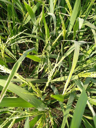

In [9]:
files = get_image_files(trn_data)
img = PILImage.create(files[4])
print(img.size)
img.to_thumb(128)

In [10]:
# we want to see what are the sizes from all of the images there
from fastcore.parallel import *

# make a funciton that returns the image size
def f(o) : return Image.open(o).size
sizes = parallel(f,files,n_workers=8) #parallel makes the operation faster
pd.Series(sizes).value_counts() # the series make the py list to df

(480, 640)    10403
(640, 480)        4
Name: count, dtype: int64

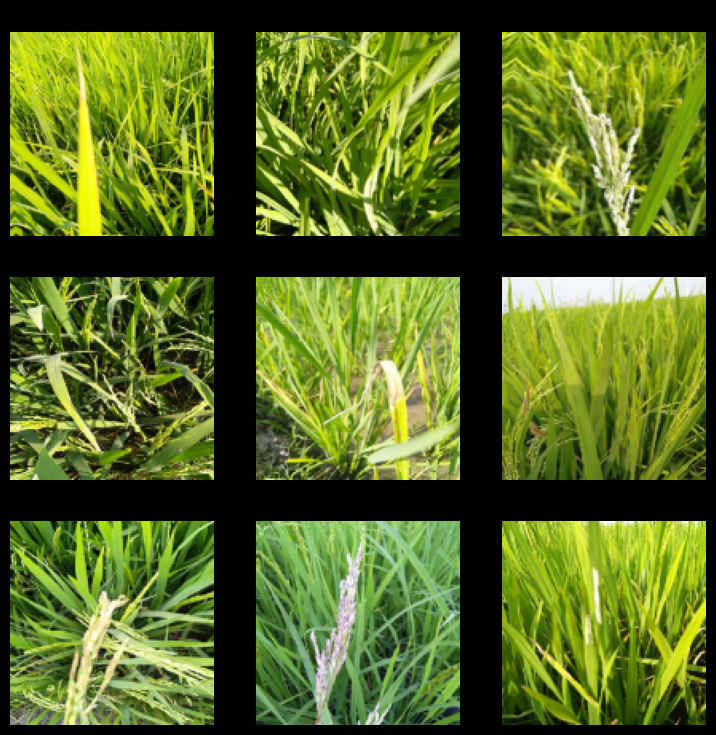

In [11]:
# the best way to solve this is not the squish , but we are going to make it as initial
dls = ImageDataLoaders.from_folder(trn_data,
                                   valid_pct=.2,
                                   item_tfms = Resize(480, method='squish'),
                                batch_tfms=aug_transforms(size=128, min_scale=0.75))

dls.show_batch(max_n=9)

## make the first model

In [12]:
#make a learner from the fast ai (get model  ,adjust the head of the model by seeing the classes form the dataloaders loss,optimizer,CARRIES THE WEIGHTS OF THE MODEL,...) --> so that we can make just model.fit
learn = vision_learner(dls,
                       "resnet26d",
                       metrics=accuracy,
                       path="../..").to_fp16() # current path

<div></div>

SuggestedLRs(valley=0.0010000000474974513, slide=0.0020892962347716093)

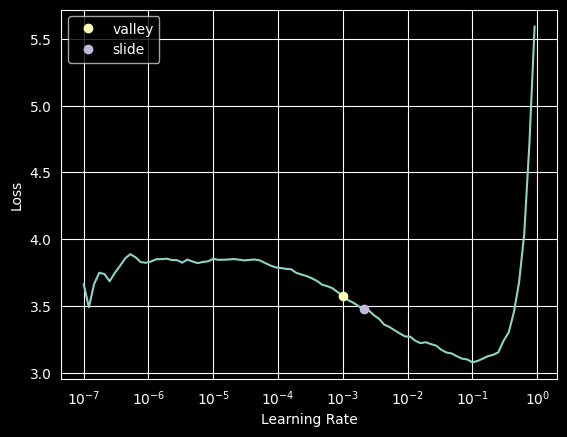

In [13]:
# now lets get the lr
learn.lr_find(suggest_funcs=(valley, slide))

```
## learn.fit ##
trains ALL layers equally (dangerous with pretrained models):
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿           BODY                      ﷿﷿﷿     HEAD     ﷿﷿﷿
﷿﷿﷿  ﷿﷿﷿ updating weights ﷿﷿﷿               ﷿﷿﷿ ﷿﷿﷿ updating ﷿﷿﷿ ﷿﷿﷿
﷿﷿﷿  DANGER: destroys pretrained knowledge!             ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
## learn.fine_tune ##
STAGE 1 ﷿﷿﷿ freeze body, only train the new head:
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿           BODY                      ﷿﷿﷿     HEAD     ﷿﷿﷿
﷿﷿﷿         FROZEN ﷿﷿﷿﷿﷿﷿                   ﷿﷿﷿ ﷿﷿﷿ updating ﷿﷿﷿ ﷿﷿﷿
﷿﷿﷿  pretrained knowledge safe          ﷿﷿﷿ learns paddy ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
STAGE 2 ﷿﷿﷿ unfreeze everything, train body with tiny LR:
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿           BODY                      ﷿﷿﷿     HEAD     ﷿﷿﷿
﷿﷿﷿  ﷿﷿﷿ tiny updates (lr/100) ﷿﷿﷿          ﷿﷿﷿ ﷿﷿﷿ updating ﷿﷿﷿ ﷿﷿﷿
﷿﷿﷿  nudges toward rice disease         ﷿﷿﷿ already good ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
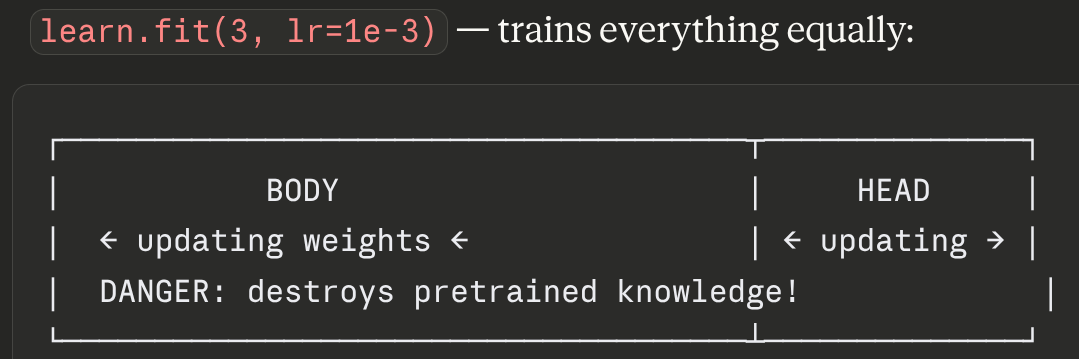
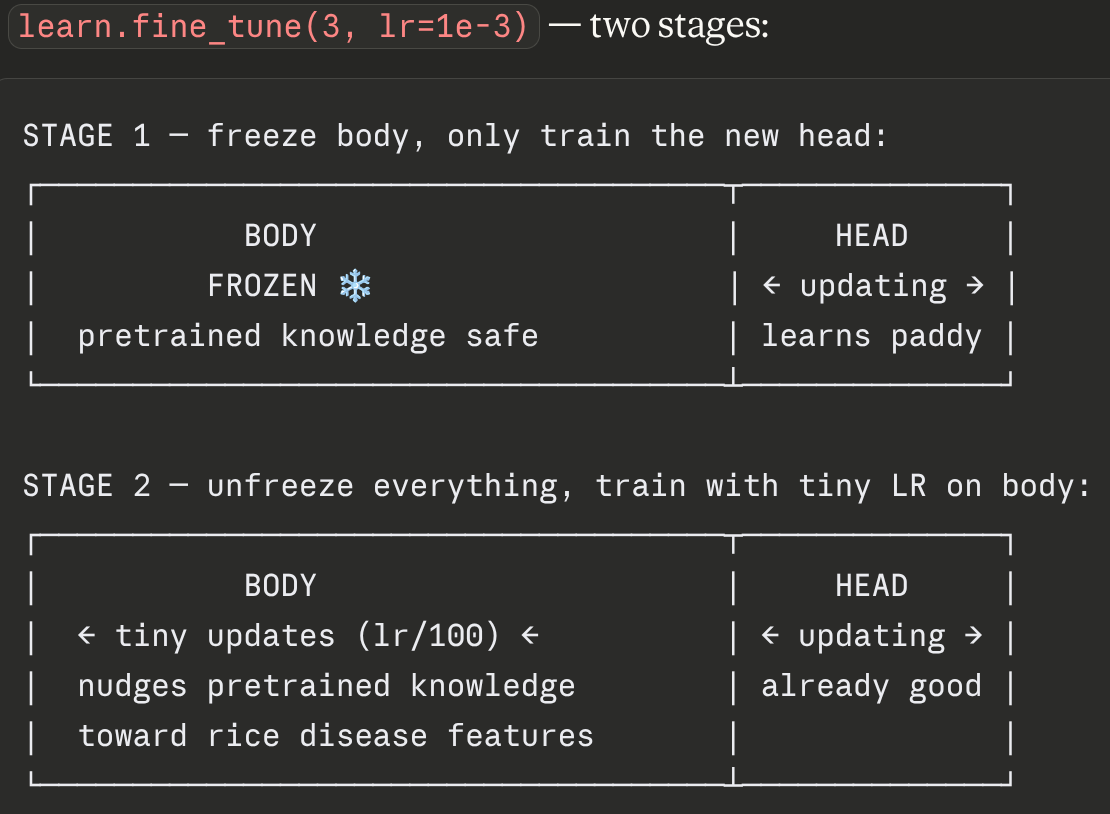

In [14]:
# lets make fine_tune
learn.fine_tune(3,0.01)

epoch,train_loss,valid_loss,accuracy,time
0,1.783786,1.386184,0.566074,00:25


epoch,train_loss,valid_loss,accuracy,time
0,1.157232,0.732249,0.761653,00:27
1,0.760385,0.475951,0.850072,00:27
2,0.553496,0.367515,0.882749,00:27


## make the kaggle submission

In [15]:
os.getcwd()

'/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai'

In [17]:
#lets see what the submission should look like
ss = pd.read_csv(Path("../Data/plant_comp/sample_submission.csv"))
ss

,image_id,label
0,200001.jpg,NaN
1,200002.jpg,NaN
2,200003.jpg,NaN
3,200004.jpg,NaN
4,200005.jpg,NaN
...,...,...
3464,203465.jpg,NaN
3465,203466.jpg,NaN
3466,203467.jpg,NaN
3467,203468.jpg,NaN


In [18]:
# 1 -- get the test images in alphabetical oreder(kaggle expects in order)
test_files = get_image_files(test_data).sorted()
# 2 -- make the test dataloader-->(same everything in the training is made by the test_dl()
test_dls = dls.test_dl(test_files)
# 3 -- run the model there and get the probs ( the _  targets (blank for test, we discard with (_)))
probs,_,idxs = learn.get_preds(dl=test_dls,
                               with_decoded=True)# this is to make the funciton give us the idxs , where it is like give us the argmax() index(the index with the highest propability)

In [20]:
# the classes
classes = dls.vocab # from fastai
classes

['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']

In [21]:
# 4 -- get the disease names from the idxs
mapping = dict(enumerate(classes)) # give {class_ind:class,.....}
mapping

{0: 'bacterial_leaf_blight',
 1: 'bacterial_leaf_streak',
 2: 'bacterial_panicle_blight',
 3: 'blast',
 4: 'brown_spot',
 5: 'dead_heart',
 6: 'downy_mildew',
 7: 'hispa',
 8: 'normal',
 9: 'tungro'}

In [22]:
results = pd.Series(idxs.numpy() , name="idxs")
results

0       7
1       8
2       4
3       3
4       3
       ..
3464    5
3465    7
3466    8
3467    1
3468    5
Name: idxs, Length: 3469, dtype: int64

# SERIES ﷿﷿﷿ one column, just values + index:
pd.Series([7, 8, 6])

# DATAFRAME ﷿﷿﷿ multiple columns, like a table:
pd.DataFrame({'image_id': ['200001.jpg', '200002.jpg'],
              'label':    ['hispa',      'normal']})

In [24]:
results = results.map(mapping) # we have to make (=) to assign the value to results
results

0                       hispa
1                      normal
2                  brown_spot
3                       blast
4                       blast
                ...          
3464               dead_heart
3465                    hispa
3466                   normal
3467    bacterial_leaf_streak
3468               dead_heart
Name: idxs, Length: 3469, dtype: str

In [25]:
# now lets make the csv
ss["label"] = results # cant make ss["label"] = results["label"] , becasue results is a series not df
ss.to_csv("submission_1.csv", index=False)

In [26]:
os.getcwd()

'/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai'

In [27]:
!head ./plant_comp/submission_1.csv

image_id,label
200001.jpg,hispa
200002.jpg,normal
200003.jpg,brown_spot
200004.jpg,blast
200005.jpg,blast
200006.jpg,brown_spot
200007.jpg,dead_heart
200008.jpg,brown_spot
200009.jpg,normal
